# What a machine cannot do, and what it cannot do in time

Theoretical computer science sounds far from data analysis. It is not: it tells
you which of your tools are guaranteed to finish, which problems have no
efficient solution however clever you are, and which questions no program can
answer at all. This notebook shows one of each.

## 1. Regular expressions are automata, except when they are not

A regular expression describes a regular language, and a finite automaton
recognizes it in one pass over the input, one step per character. Python's `re`
does not build the automaton; it tries alternatives and backtracks. For most
patterns the difference is invisible. Here is a pattern where it is not:
`(a+)+b` on a string of a's with no b at the end.

In [1]:
import re, time

pattern = re.compile(r"(a+)+b")
ns = list(range(10, 25, 2))
seconds = []
for n in ns:
    t0 = time.perf_counter()
    pattern.fullmatch("a" * n)                   # there is no b, so the answer is None
    seconds.append(time.perf_counter() - t0)
    print(f"{n} a's: {seconds[-1]:8.4f} s")

10 a's:   0.0001 s
12 a's:   0.0004 s
14 a's:   0.0014 s
16 a's:   0.0057 s
18 a's:   0.0230 s
20 a's:   0.0834 s


22 a's:   0.3388 s
24 a's:   1.3012 s


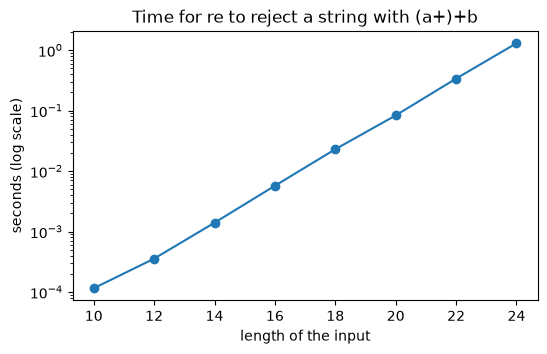

two extra characters multiply the time by about 3.8


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ns, seconds, "o-")
ax.set_yscale("log"); ax.set_xlabel("length of the input"); ax.set_ylabel("seconds (log scale)")
ax.set_title("Time for re to reject a string with (a+)+b")
plt.show()
print(f"two extra characters multiply the time by about {seconds[-1] / seconds[-2]:.1f}")

Every two extra characters multiply the time by about four: the time is $2^n$.
A string of 40 a's would take years, and a true automaton would reject it in 40
steps. The difference is that the automaton has one state per position, and
the backtracking matcher explores every way of splitting the a's into groups.
This is exactly the failure that took down a large part of the web in 2019
(motivating example A of the lecture). The lesson is not to avoid regular
expressions, which are the right tool for tokenizing and validating text, but to
know that a pattern with nested repetition can be exponential in `re`, while
engines built as automata (Google's RE2, Rust's `regex`) cannot.

## 2. Easy to check, hard to find

Split a seminar of $n$ students into two groups with the same total number of
credit points. Given a proposed split, checking it is one addition per student.
Finding one is another matter: the only general method known tries subsets, and
there are $2^n$ of them. This is the partition problem, one of the classic
NP-complete problems, and the code below shows what NP-complete feels like.

In [3]:
import random
from itertools import combinations

rnd = random.Random(9)

def find_split(points):
    total = sum(points)
    if total % 2:
        return None
    n = len(points)
    for k in range(1, n // 2 + 1):                            # try every subset, smallest first
        for group in combinations(range(n), k):
            if sum(points[i] for i in group) == total // 2:
                return group
    return None

def check_split(points, group):                               # the verifier
    return 2 * sum(points[i] for i in group) == sum(points)

ns = list(range(12, 23, 2))
times = []
for n in ns:
    points = [rnd.randrange(50, 200) * 2 for _ in range(n)]
    points[0] = sum(points[1:]) + 2                           # one student outweighs all others: no split exists
    t0 = time.perf_counter(); find_split(points); times.append(time.perf_counter() - t0)
    print(f"n = {n:2}: no split, searched all subsets in {times[-1]:7.3f} s")

n = 12: no split, searched all subsets in   0.003 s
n = 14: no split, searched all subsets in   0.012 s
n = 16: no split, searched all subsets in   0.047 s


n = 18: no split, searched all subsets in   0.196 s


n = 20: no split, searched all subsets in   0.804 s


n = 22: no split, searched all subsets in   3.557 s


In [4]:
half = [rnd.randrange(50, 200) for _ in range(12)]
points = half + half                                          # 24 students; a split certainly exists
rnd.shuffle(points)
group = find_split(points)
t0 = time.perf_counter()
for _ in range(1000): ok = check_split(points, group)
t_check = (time.perf_counter() - t0) / 1000
print("proposed group:", group, "valid:", ok)
print(f"checking takes {t_check * 1e6:.1f} microseconds")
doubling = (times[-1] / times[0]) ** (1 / (ns[-1] - ns[0]))
print(f"search time grows by a factor of {doubling:.2f} per extra student; for 60 students: "
      f"{times[-1] * doubling ** (60 - ns[-1]) / 3.15e7:,.0f} years")

proposed group: (0, 5, 6, 7, 9, 11, 13, 15, 16, 21) valid: True
checking takes 3.1 microseconds
search time grows by a factor of 2.05 per extra student; for 60 students: 80,192 years


Checking is instant, finding takes time that multiplies with every student
added. That asymmetry is the definition of NP: a yes answer has a certificate
that is quick to verify. Whether finding can be made as fast as checking is the
P versus NP question, and nobody knows. What you should know is how to
recognize the shape: scheduling, grouping, routing and covering problems on
social data very often are NP-complete, and when your exact solver works on 20
cases and hangs on 60, the answer is not a faster loop but an approximate
method, a heuristic, or a smaller question.

## 3. No program can tell whether a program stops

The halting problem says that no program can decide, for every program and
input, whether it eventually stops. Here is what that means in practice. The
function below halves even numbers and triples-plus-one odd numbers until it
reaches 1. Does it stop for every starting value? We can test as many values as
we like.

In [5]:
def steps_to_one(n):
    steps = 0
    while n != 1:
        n = n // 2 if n % 2 == 0 else 3 * n + 1
        steps += 1
    return steps

checked = 200_000
longest = max(range(1, checked + 1), key=steps_to_one)
print(f"every start up to {checked:,} stops; the slowest is {longest} with {steps_to_one(longest)} steps")

every start up to 200,000 stops; the slowest is 156159 with 382 steps


Two hundred thousand tests, all of them stop, and that proves nothing about the
next value; whether this loop stops for every $n$ is an open problem in
mathematics (the Collatz conjecture). The computer cannot settle it by running
the program, and by the halting theorem no program can settle such questions in
general. In practice this is why every job scheduler and every notebook has a
timeout and not a "hang detector": when your script has run for an hour, no
tool can tell you whether it is slow or stuck. Only you can, by reasoning about
the code, which is what the rest of the course is for.

**What we used:** finite-state automata and regular languages
([session 9, sections 2 and 5](../Transcripts/09-TheoreticalCS.md#5-regular-languages)),
computability and the halting problem ([section 7](../Transcripts/09-TheoreticalCS.md#7-computability)),
complexity classes, P, NP and NP-completeness ([section 9](../Transcripts/09-TheoreticalCS.md#9-complexity-classes)),
and the motivating example of the regular expression that took down a large part of the web.